In [3]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [4]:
# Load patient and cluster data

patients = pd.read_csv("../dataset/patients.csv")

hospitals = pd.read_csv("../dataset/hospitals.csv")

opd = pd.read_csv("../outputs/cleaned_data/opd_cleaned.csv")

billing = pd.read_csv("../outputs/cleaned_data/billing_cleaned.csv")

clustered_patients = pd.read_csv(
    "../outputs/clustered_patient_features.csv"
)

print("Patients:", patients.shape)
print("Hospitals:", hospitals.shape)
print("OPD:", opd.shape)
print("Billing:", billing.shape)
print("Clustered Patients:", clustered_patients.shape)

Patients: (50000, 5)
Hospitals: (4, 4)
OPD: (180000, 8)
Billing: (160000, 11)
Clustered Patients: (50000, 15)


In [5]:
# Display column names of all datasets

print("Patient Columns:")
print(patients.columns.tolist())

print("\nHospital Columns:")
print(hospitals.columns.tolist())

print("\nOPD Columns:")
print(opd.columns.tolist())

print("\nBilling Columns:")
print(billing.columns.tolist())

print("\nClustered Patient Columns:")
print(clustered_patients.columns.tolist())

Patient Columns:
['patient_id', 'home_hospital_id', 'gender', 'age_or_dob', 'patient_profile_simulation_only']

Hospital Columns:
['hospital_id', 'hospital_name', 'city', 'bed_capacity']

OPD Columns:
['visit_id', 'patient_id', 'hospital_id', 'doctor_id', 'department_id', 'visit_date', 'diagnosis_text', 'visit_type']

Billing Columns:
['bill_id', 'patient_id', 'hospital_id', 'doctor_id', 'department_id', 'bill_date', 'base_amount', 'gst_rate', 'amount_recorded', 'corrected_amount', 'gst_issue']

Clustered Patient Columns:
['patient_id', 'home_hospital_id', 'gender', 'age', 'Recency', 'Frequency', 'Monetary', 'Admission_Frequency', 'Average_LOS', 'Lab_Frequency', 'Growth', 'Seasonality', 'No_Growth_Baseline', 'Has_OPD_Visit', 'Cluster']


In [6]:
# Display hospital information

display(hospitals)

print("\nNumber of Hospitals:", len(hospitals))

,hospital_id,hospital_name,city,bed_capacity
0,H001,Hyderabad Central Hospital,Hyderabad,250
1,H002,Secunderabad Care Hospital,Hyderabad,180
2,H003,Kukatpally Community Hospital,Hyderabad,200
3,H004,LB Nagar Community Hospital,Hyderabad,150



Number of Hospitals: 4


In [7]:
# Merge original patient data with cluster assignments

patient_cluster_data = patients.merge(
    clustered_patients[["patient_id", "Cluster"]],
    on="patient_id",
    how="inner"
)

print("Merged Dataset Shape:", patient_cluster_data.shape)

display(patient_cluster_data.head())

Merged Dataset Shape: (50000, 6)


,patient_id,home_hospital_id,gender,age_or_dob,patient_profile_simulation_only,Cluster
0,P000001,H004,Male,60,Routine_Care,3
1,P000002,H002,Male,1996-07-04,Low_Utilization,3
2,P000003,H003,Male,28,Frequent_Care,1
3,P000004,H001,Female,1990-07-11,Routine_Care,3
4,P000005,H002,Male,1991-05-21,Low_Utilization,3


In [9]:
# Count patients according to their home hospital

hospital_patient_count = (
    patient_cluster_data.groupby("home_hospital_id")["patient_id"]
    .nunique()
    .reset_index(name="Patient_Count")
)

# Rename column for consistent reporting

hospital_patient_count = hospital_patient_count.rename(
    columns={"home_hospital_id": "hospital_id"}
)

# Calculate percentage

hospital_patient_count["Percentage"] = (
    hospital_patient_count["Patient_Count"]
    / hospital_patient_count["Patient_Count"].sum() * 100
).round(2)

display(hospital_patient_count)

,hospital_id,Patient_Count,Percentage
0,H001,15926,31.85
1,H002,11532,23.06
2,H003,12565,25.13
3,H004,9977,19.95


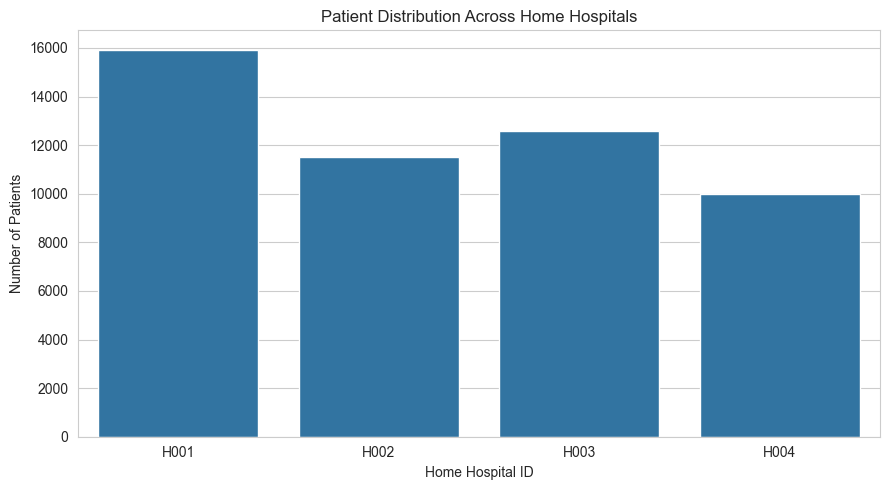

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=hospital_patient_count,
    x="hospital_id",
    y="Patient_Count"
)

plt.title("Patient Distribution Across Home Hospitals")
plt.xlabel("Home Hospital ID")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [11]:
# Cluster distribution by home hospital

hospital_cluster = pd.crosstab(
    patient_cluster_data["home_hospital_id"],
    patient_cluster_data["Cluster"]
)

display(hospital_cluster)

Cluster,0,1,2,3
home_hospital_id,,,,
H001,1477,6616,1486,6347
H002,1130,4768,1112,4522
H003,1173,5191,1177,5024
H004,933,4142,948,3954


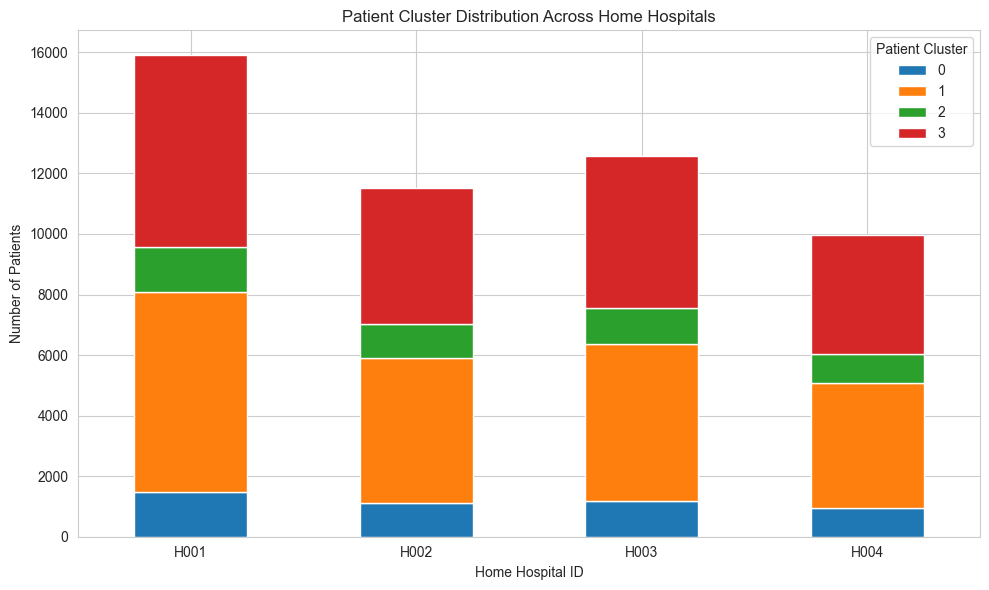

In [12]:
# Visualize cluster distribution by home hospital

hospital_cluster.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Patient Cluster Distribution Across Home Hospitals")
plt.xlabel("Home Hospital ID")
plt.ylabel("Number of Patients")

plt.legend(title="Patient Cluster")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [13]:
# Calculate total OPD visits for each hospital

hospital_opd = (
    opd.groupby("hospital_id")
    .size()
    .reset_index(name="Total_OPD_Visits")
)

display(hospital_opd)

,hospital_id,Total_OPD_Visits
0,H001,57275
1,H002,41516
2,H003,45383
3,H004,35826


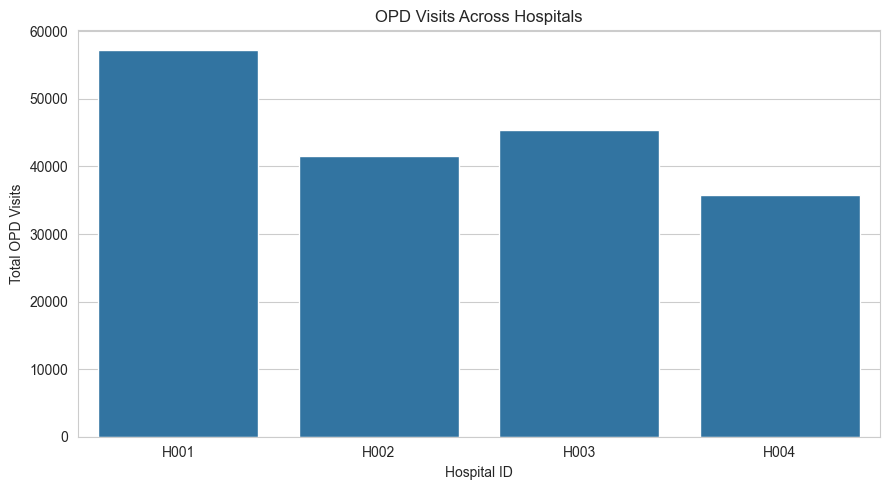

In [14]:
# Plot hospital-wise OPD visits

plt.figure(figsize=(9, 5))

sns.barplot(
    data=hospital_opd,
    x="hospital_id",
    y="Total_OPD_Visits"
)

plt.title("OPD Visits Across Hospitals")
plt.xlabel("Hospital ID")
plt.ylabel("Total OPD Visits")

plt.tight_layout()
plt.show()

In [15]:
# Check available billing columns

print("Billing Columns:")
print(billing.columns.tolist())

if "corrected_amount" in billing.columns:
    amount_column = "corrected_amount"
elif "base_amount" in billing.columns:
    amount_column = "base_amount"
else:
    raise ValueError("No suitable billing amount column found.")

print("\nSelected Billing Column:", amount_column)

Billing Columns:
['bill_id', 'patient_id', 'hospital_id', 'doctor_id', 'department_id', 'bill_date', 'base_amount', 'gst_rate', 'amount_recorded', 'corrected_amount', 'gst_issue']

Selected Billing Column: corrected_amount


In [16]:
# Calculate total billing for each hospital

hospital_billing = (
    billing.groupby("hospital_id")[amount_column]
    .sum()
    .reset_index(name="Total_Billing")
)

hospital_billing["Total_Billing"] = (
    hospital_billing["Total_Billing"].round(2)
)

display(hospital_billing)

,hospital_id,Total_Billing
0,H001,1.435995e+08
1,H002,1.043355e+08
2,H003,1.153716e+08
3,H004,9.097278e+07


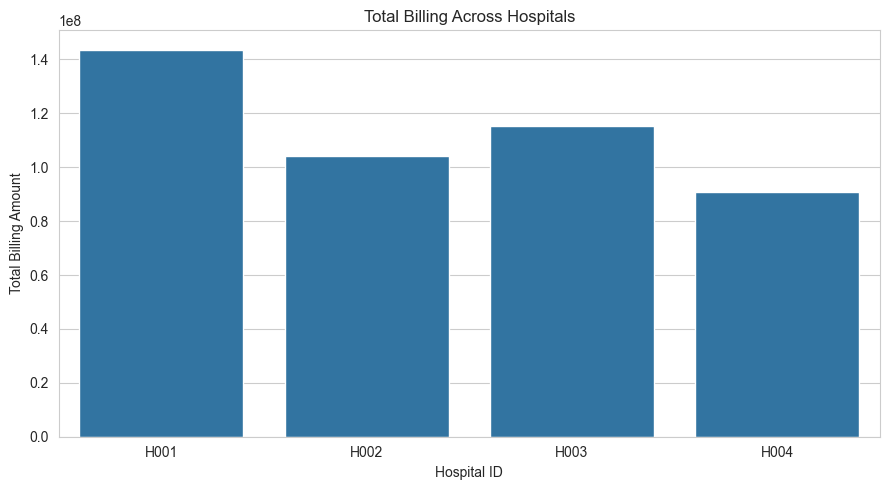

In [17]:
# Plot total billing across hospitals

plt.figure(figsize=(9, 5))

sns.barplot(
    data=hospital_billing,
    x="hospital_id",
    y="Total_Billing"
)

plt.title("Total Billing Across Hospitals")
plt.xlabel("Hospital ID")
plt.ylabel("Total Billing Amount")

plt.tight_layout()
plt.show()

In [18]:
# Calculate average billing per record for each hospital

average_billing = (
    billing.groupby("hospital_id")[amount_column]
    .mean()
    .reset_index(name="Average_Billing")
)

average_billing["Average_Billing"] = (
    average_billing["Average_Billing"].round(2)
)

display(average_billing)

,hospital_id,Average_Billing
0,H001,2822.71
1,H002,2833.82
2,H003,2842.16
3,H004,2868.36


In [19]:
# Combine hospital-wise patient, OPD and billing summaries

hospital_summary = hospital_patient_count.merge(
    hospital_opd,
    on="hospital_id",
    how="outer"
)

hospital_summary = hospital_summary.merge(
    hospital_billing,
    on="hospital_id",
    how="outer"
)

hospital_summary = hospital_summary.merge(
    average_billing,
    on="hospital_id",
    how="outer"
)

display(hospital_summary.round(2))

,hospital_id,Patient_Count,Percentage,Total_OPD_Visits,Total_Billing,Average_Billing
0,H001,15926,31.85,57275,1.435995e+08,2822.71
1,H002,11532,23.06,41516,1.043355e+08,2833.82
2,H003,12565,25.13,45383,1.153716e+08,2842.16
3,H004,9977,19.95,35826,9.097278e+07,2868.36


In [20]:
print(hospitals.columns.tolist())

['hospital_id', 'hospital_name', 'city', 'bed_capacity']


In [21]:
# Add hospital names to the summary

hospital_summary = hospital_summary.merge(
    hospitals[["hospital_id", "hospital_name"]],
    on="hospital_id",
    how="left"
)

display(hospital_summary)

,hospital_id,Patient_Count,Percentage,Total_OPD_Visits,Total_Billing,Average_Billing,hospital_name
0,H001,15926,31.85,57275,1.435995e+08,2822.71,Hyderabad Central Hospital
1,H002,11532,23.06,41516,1.043355e+08,2833.82,Secunderabad Care Hospital
2,H003,12565,25.13,45383,1.153716e+08,2842.16,Kukatpally Community Hospital
3,H004,9977,19.95,35826,9.097278e+07,2868.36,LB Nagar Community Hospital


In [22]:
# Save hospital-wise summary

hospital_summary.to_csv(
    "../outputs/hospital_wise_summary.csv",
    index=False
)

# Save cluster distribution by home hospital

hospital_cluster.to_csv(
    "../outputs/hospital_cluster_distribution.csv"
)

print("Hospital-wise reports saved successfully!")

Hospital-wise reports saved successfully!


In [23]:
# Validate hospital-wise analysis

print("Number of Hospitals:", hospitals.shape[0])

print("Total Patients:", patients["patient_id"].nunique())

print("Total Clustered Patients:",
      clustered_patients["patient_id"].nunique())

print("Total OPD Records:", len(opd))

print("Total Billing Records:", len(billing))

print("\nFinal Hospital Summary:")
display(hospital_summary)

Number of Hospitals: 4
Total Patients: 50000
Total Clustered Patients: 50000
Total OPD Records: 180000
Total Billing Records: 160000

Final Hospital Summary:


,hospital_id,Patient_Count,Percentage,Total_OPD_Visits,Total_Billing,Average_Billing,hospital_name
0,H001,15926,31.85,57275,1.435995e+08,2822.71,Hyderabad Central Hospital
1,H002,11532,23.06,41516,1.043355e+08,2833.82,Secunderabad Care Hospital
2,H003,12565,25.13,45383,1.153716e+08,2842.16,Kukatpally Community Hospital
3,H004,9977,19.95,35826,9.097278e+07,2868.36,LB Nagar Community Hospital
